In [10]:
import os
for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.lower().endswith((".csv", ".zip")):
            print(os.path.join(root, file))

/content/creditcard.csv.zip
/content/creditcard.csv
/content/sample_data/california_housing_test.csv
/content/sample_data/mnist_test.csv
/content/sample_data/mnist_train_small.csv
/content/sample_data/california_housing_train.csv


In [11]:
import zipfile
import os
zip_path = "/content/creditcard.csv.zip"
extract_folder = "/content/clean_dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_folder)
print("Extracted files:")
print(os.listdir(extract_folder))

Extracted files:
['creditcard.csv']


In [12]:
import pandas as pd
df = pd.read_csv("/content/clean_dataset/creditcard.csv")
print("Dataset shape:", df.shape)
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\nTransaction counts:")
print(df["Class"].value_counts().sort_index())
print("\nTransaction percentages:")
print(
    (df["Class"].value_counts(normalize=True).sort_index() * 100).round(4))

Dataset shape: (284807, 31)
Total missing values: 0
Duplicate rows: 1081

Transaction counts:
Class
0    284315
1       492
Name: count, dtype: int64

Transaction percentages:
Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64


In [13]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

In [14]:
!pip install imbalanced-learn

In [15]:
X = df.drop("Class", axis=1)
y = df["Class"]
print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())

Features shape: (284807, 30)
Target shape: (284807,)

Target distribution:
Class
0    284315
1       492
Name: count, dtype: int64


In [16]:
X_train, X_test, y_train, y_test = train_test_split(X,y,
    test_size=0.20,
    random_state=42,
    stratify=y)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("\nFraud cases in training data:")
print(y_train.value_counts())
print("\nFraud cases in testing data:")
print(y_test.value_counts())

Training features: (227845, 30)
Testing features: (56962, 30)

Fraud cases in training data:
Class
0    227451
1       394
Name: count, dtype: int64

Fraud cases in testing data:
Class
0    56864
1       98
Name: count, dtype: int64


In [17]:
scaler = StandardScaler()
X_train[["Time", "Amount"]] = scaler.fit_transform(
    X_train[["Time", "Amount"]])
X_test[["Time", "Amount"]] = scaler.transform(
    X_test[["Time", "Amount"]])
print("Scaling completed.")
print(X_train[["Time", "Amount"]].head())

Scaling completed.
            Time    Amount
265518  1.411588 -0.322494
180305  0.623141 -0.339764
42664  -1.130680  0.346693
198723  0.794699 -0.327360
82325  -0.748102 -0.008281


In [18]:
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train,
    y_train)
print("Before SMOTE:")
print(y_train.value_counts())
print("\nAfter SMOTE:")
print(y_train_balanced.value_counts())
print("\nBalanced training shape:", X_train_balanced.shape)

Before SMOTE:
Class
0    227451
1       394
Name: count, dtype: int64

After SMOTE:
Class
0    227451
1    227451
Name: count, dtype: int64

Balanced training shape: (454902, 30)


In [19]:
print("Training data after SMOTE:")
print(y_train_balanced.value_counts())
print("\nTest data (unchanged):")
print(y_test.value_counts())
print("\nMissing values in training data:", X_train_balanced.isnull().sum().sum())
print("Missing values in test data:", X_test.isnull().sum().sum())

Training data after SMOTE:
Class
0    227451
1    227451
Name: count, dtype: int64

Test data (unchanged):
Class
0    56864
1       98
Name: count, dtype: int64

Missing values in training data: 0
Missing values in test data: 0


In [20]:
from sklearn.linear_model import LogisticRegression
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42)
lr_model.fit(X_train_balanced, y_train_balanced)
print("Logistic Regression training completed.")

Logistic Regression training completed.


In [21]:
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1)
rf_model.fit(X_train_balanced, y_train_balanced)
print("Random Forest training completed.")

Random Forest training completed.


In [26]:
lr_predictions = lr_model.predict(X_test)
rf_predictions = rf_model.predict(X_test)
print("Predictions completed for both models.")

Predictions completed for both models.


In [27]:
from sklearn.metrics import classification_report

print("=== LOGISTIC REGRESSION ===")
print(classification_report(
    y_test, lr_predictions,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

print("=== RANDOM FOREST ===")
print(classification_report(
    y_test, rf_predictions,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

=== LOGISTIC REGRESSION ===
              precision    recall  f1-score   support

  Legitimate       1.00      0.97      0.99     56864
       Fraud       0.06      0.92      0.11        98

    accuracy                           0.97     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.97      0.99     56962

=== RANDOM FOREST ===
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
       Fraud       0.85      0.84      0.84        98

    accuracy                           1.00     56962
   macro avg       0.92      0.92      0.92     56962
weighted avg       1.00      1.00      1.00     56962



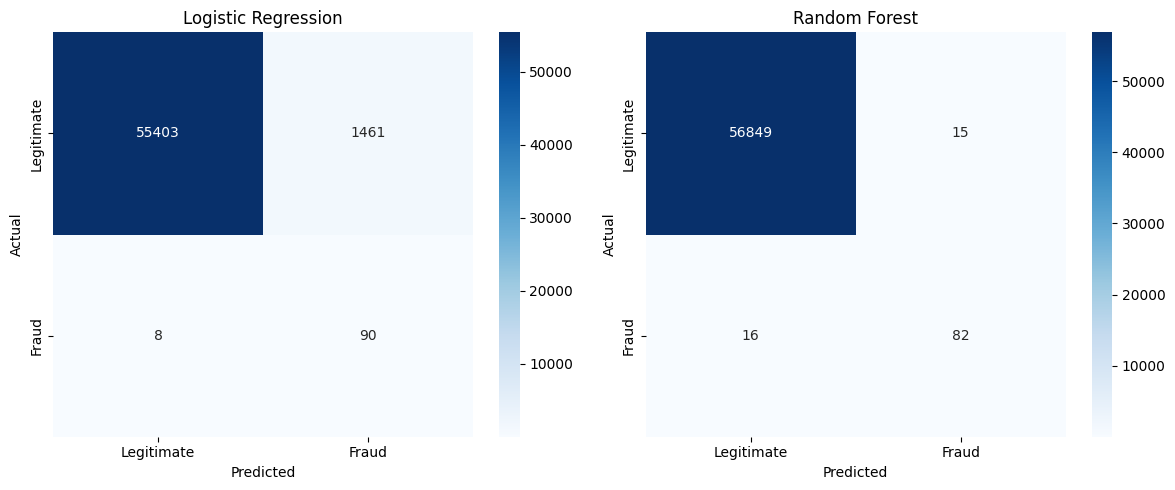

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, name, predictions in [
    (axes[0], "Logistic Regression", lr_predictions),
    (axes[1], "Random Forest", rf_predictions)
]:
    cm = confusion_matrix(y_test, predictions)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=["Legitimate", "Fraud"],
        yticklabels=["Legitimate", "Fraud"],
        ax=ax
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [29]:

import pandas as pd
from sklearn.metrics import confusion_matrix
chosen_predictions = pd.Series(
    rf_predictions,
    index=X_test.index)
tn, fp, fn, tp = confusion_matrix(
    y_test, chosen_predictions
).ravel()
print("=== RANDOM FOREST BUSINESS IMPACT ===")
print("Legitimate transactions correctly identified:", tn)
print("Legitimate transactions incorrectly flagged:", fp)
print("Fraud transactions missed:", fn)
print("Fraud transactions detected:", tp)
original_amounts = df.loc[X_test.index, "Amount"]
actual_fraud = y_test == 1
caught_fraud = actual_fraud & (chosen_predictions == 1)
missed_fraud = actual_fraud & (chosen_predictions == 0)
print("\nFraud detection rate:", round(tp / (tp + fn) * 100, 2), "%")
print(
    "Value of detected fraud transactions:",
    round(original_amounts.loc[caught_fraud].sum(), 2))
print(
    "Value of missed fraud transactions:",
    round(original_amounts.loc[missed_fraud].sum(), 2))

=== RANDOM FOREST BUSINESS IMPACT ===
Legitimate transactions correctly identified: 56849
Legitimate transactions incorrectly flagged: 15
Fraud transactions missed: 16
Fraud transactions detected: 82

Fraud detection rate: 83.67 %
Value of detected fraud transactions: 6813.48
Value of missed fraud transactions: 3831.45


In [30]:
import joblib
joblib.dump(rf_model, "credit_card_fraud_model.pkl")
joblib.dump(scaler, "credit_card_fraud_scaler.pkl")
joblib.dump(list(X.columns), "credit_card_fraud_features.pkl")
print("Model and preprocessing files saved successfully!")

Model and preprocessing files saved successfully!


In [31]:
from google.colab import files
files.download("credit_card_fraud_model.pkl")
files.download("credit_card_fraud_scaler.pkl")
files.download("credit_card_fraud_features.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:

import joblib
import pandas as pd
loaded_model = joblib.load("credit_card_fraud_model.pkl")
loaded_scaler = joblib.load("credit_card_fraud_scaler.pkl")
loaded_features = joblib.load("credit_card_fraud_features.pkl")
sample_transactions = X_test[loaded_features].head(10)
predictions = loaded_model.predict(sample_transactions)
results = pd.DataFrame({
    "Transaction": range(1, 11),
    "Prediction": [
        "Fraud" if value == 1 else "Legitimate"
        for value in predictions
    ]})
print("Saved model loaded and tested successfully!")
display(results)

Saved model loaded and tested successfully!


,Transaction,Prediction
0,1,Legitimate
1,2,Legitimate
2,3,Legitimate
3,4,Legitimate
4,5,Legitimate
5,6,Legitimate
6,7,Legitimate
7,8,Legitimate
8,9,Legitimate
9,10,Legitimate


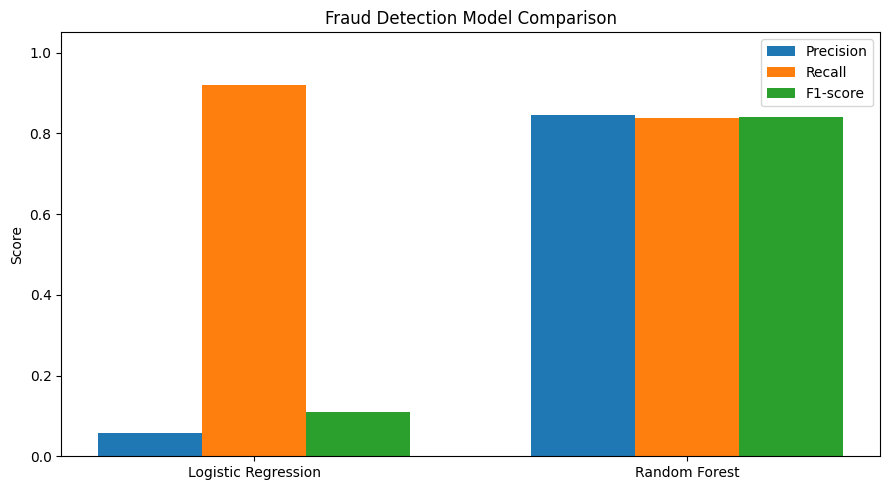

Comparison chart saved as model_comparison.png


In [33]:

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score
models = ["Logistic Regression", "Random Forest"]
fraud_precision = [
    precision_score(y_test, lr_predictions, zero_division=0),
    precision_score(y_test, rf_predictions, zero_division=0)]
fraud_recall = [
    recall_score(y_test, lr_predictions, zero_division=0),
    recall_score(y_test, rf_predictions, zero_division=0)]
fraud_f1 = [
    f1_score(y_test, lr_predictions, zero_division=0),
    f1_score(y_test, rf_predictions, zero_division=0)]
x = np.arange(len(models))
width = 0.24
plt.figure(figsize=(9, 5))
plt.bar(x - width, fraud_precision, width, label="Precision")
plt.bar(x, fraud_recall, width, label="Recall")
plt.bar(x + width, fraud_f1, width, label="F1-score")
plt.xticks(x, models)
plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.title("Fraud Detection Model Comparison")
plt.legend()
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()
print("Comparison chart saved as model_comparison.png")